# Jetsound: Sound detection with Jetson Nano

## Data collection and feature extraction

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.io import wavfile
from scipy.signal import stft
import os

#DATADIR = "FinalAssignment/dataset/"
# DATADIR = "Haakons_testfolder/instrument_set/"
# print(DATADIR)
# CATEGORIES = ['Acoustic_guitar', 'Drum_set', 'vibraphone']

#DATADIR = "FinalAssignment/dataset/"
DATADIR = "../FinalAssignment/dataset/"
print(DATADIR)
CATEGORIES = ['Claps', 'Keyboard', 'Keys']

FinalAssignment/dataset/


Function to make spectrograms.

In [2]:
# Library-less alternative
# Convert frequency in Hz to Mel scale
def hz_to_mel(f):
    return 2595.0 * np.log10(1.0 + f / 700.0)

# Convert Mel scale back to frequency in Hz
def mel_to_hz(m):
    return 700.0 * (10.0**(m / 2595.0) - 1.0)

def mel_filterbank(n_mels, n_fft, sample_rate, fmax):
    """
    Create a Mel filterbank matrix to convert FFT bins to Mel bins.
    
    Parameters:
        n_mels: number of Mel bands
        n_fft: FFT size
        sample_rate: sampling rate of audio
        fmax: max frequency to include in Mel scale
    
    Returns:
        filterbank: shape (n_mels, n_fft//2+1)
    """
    # Convert min and max frequencies to Mel scale
    mel_min = hz_to_mel(0)
    mel_max = hz_to_mel(fmax)

    # Equally spaced points in Mel scale
    mel_points = np.linspace(mel_min, mel_max, n_mels + 2)

    # Convert Mel points back to Hz
    hz_points = mel_to_hz(mel_points)

    # Map Hz points to nearest FFT bin indices
    bin_points = np.round((n_fft + 1) * hz_points / sample_rate).astype(int)

    # Initialize filterbank matrix
    filterbank = np.zeros((n_mels, n_fft // 2 + 1))

    # Create triangular filters
    for m in range(1, n_mels + 1):
        f_left = bin_points[m - 1]     # left edge of triangle
        f_center = bin_points[m]       # center (peak) of triangle
        f_right = bin_points[m + 1]    # right edge of triangle

        # Avoid zero-width triangles
        if f_center == f_left:
            f_center += 1
        if f_right == f_center:
            f_right += 1

        # Rising slope
        for k in range(f_left, f_center):
            filterbank[m - 1, k] = (k - f_left) / (f_center - f_left)

        # Falling slope
        for k in range(f_center, f_right):
            filterbank[m - 1, k] = (f_right - k) / (f_right - f_center)

    return filterbank

def generate_mel_spectrogram(
    audio_signal,  # path to WAV file
    sample_rate,   # expected sample rate
    n_mels,        # number of Mel bins
    fmax,          # max frequency for Mel scale
    n_fft=2048,    # FFT window size
    hop_length=256 # hop length between frames
):
    # --- Load WAV file ---
    sr, signal = wavfile.read(audio_signal)

    # Check that WAV matches expected sample rate
    if sr != sample_rate:
        raise ValueError("Provided sample_rate does not match WAV file")

    # If stereo, convert to mono by averaging channels
    if signal.ndim == 2:
        signal = signal.mean(axis=1)

    # Ensure signal is float32 for processing
    signal = signal.astype(np.float32)

    # --- Compute STFT ---
    # Returns frequency bins (f), time bins (t), and complex STFT matrix (Zxx)
    _, _, Zxx = stft(
        signal,
        fs=sample_rate,
        nperseg=n_fft,
        noverlap=n_fft - hop_length,
        window="hann",
        padded=False,
        boundary=None
    )

    # --- Compute power spectrogram ---
    # Take magnitude squared of STFT
    power_spec = np.abs(Zxx) ** 2

    # --- Apply Mel filterbank ---
    mel_fb = mel_filterbank(n_mels, n_fft, sample_rate, fmax)
    # Multiply filterbank with power spectrogram
    mel_spec = np.dot(mel_fb, power_spec)

    # --- Convert to decibels (dB) ---
    mel_spec = 10.0 * np.log10(mel_spec + 1e-10)  # avoid log(0)

    # --- Normalize to [0, 1] ---
    mel_spec -= mel_spec.min()
    mel_spec /= mel_spec.max() + 1e-10

    # --- Add channel dimension for ML ---
    mel_spec = mel_spec[:, :, np.newaxis]

    return mel_spec


44100


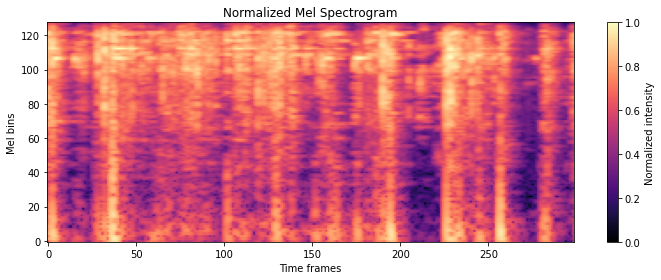

In [ ]:
# display output of function
from scipy.io import wavfile

EXAMPLEFILE = "FinalAssignment/dataset/Claps/Claps6_chunk025.wav"

sample_rate, _ = wavfile.read(EXAMPLEFILE)

print(sample_rate) # is 44100
n_mels = 128
fmax = 8000

mel_spec = generate_mel_spectrogram(
    audio_signal=EXAMPLEFILE,
    sample_rate=sample_rate,
    n_mels=n_mels,
    fmax=fmax
)

# --- Visualization ---
plt.figure(figsize=(10, 4))
# mel_spec has shape (n_mels, time_steps, 1), squeeze last dim
plt.imshow(mel_spec[:, :, 0], origin='lower', aspect='auto', cmap='magma')
plt.colorbar(label='Normalized intensity')
plt.xlabel("Time frames")
plt.ylabel("Mel bins")
plt.title("Normalized Mel Spectrogram")
plt.tight_layout()
plt.show()

In [5]:
# V2

# Parameters
N_MELS = 128
T_SAMP = 150  # Not used yet; can pad/truncate time dimension later if needed
LOSO_ID = 6   # Recording ID to leave out for testing
#CATEGORIES = ["./claps", "./snaps"]  # example paths

# Datasets
dataset = []
test_dataset = []

def create_dataset():
    """
    Creates training and test datasets from audio files in DATADIR.
    Each entry is a tuple: (mel_spec, label)
    """
    global dataset, test_dataset
    dataset = []
    test_dataset = []

    for label, category in enumerate(CATEGORIES):
        categoryfolder = os.path.join(DATADIR, category)
        if not os.path.isdir(categoryfolder):
            print(f"Warning: folder {categoryfolder} does not exist, skipping")
            continue

        for filename in os.listdir(categoryfolder):
            if not filename.lower().endswith(".wav"):
                continue  # skip non-wav files

            file_path = os.path.join(categoryfolder, filename)

            # --- Extract recording ID from filename ---
            # Example: "Claps3_chunk000.wav" -> ID=3
            try:
                # Remove category name from start
                rest = filename[len(category):]
                # Take first number in the rest as ID
                ID_str = ''.join([c for c in rest if c.isdigit()])
                ID = int(ID_str[0])  # first digit
            except:
                ID = None

            # --- Generate Mel spectrogram ---
            try:
                mel_spec = generate_mel_spectrogram(
                    audio_signal=file_path,
                    sample_rate=44100,
                    n_mels=N_MELS,
                    fmax=8000,
                    n_fft=2048,
                    hop_length=512
                )

                # --- Pad or truncate to T_SAMP ---
                time_steps = mel_spec.shape[1]
                if time_steps < T_SAMP:
                    pad_width = T_SAMP - time_steps
                    mel_spec = np.pad(mel_spec, ((0,0),(0,pad_width),(0,0)), mode='constant')
                elif time_steps > T_SAMP:
                    mel_spec = mel_spec[:, :T_SAMP, :]

            except Exception as e:
                print(f"Error processing {file_path}: {e}")
                continue

            # --- Assign to dataset or test_dataset ---
            if LOSO_ID is not None and ID == LOSO_ID:
                test_dataset.append((mel_spec, label))
            else:
                dataset.append((mel_spec, label))

    # --- Print dataset info ---
    print(f"Training dataset size: {len(dataset)}")
    print(f"Test dataset size: {len(test_dataset)}")
    
    if len(dataset) > 0:
        print(f"Shape of one training entry: {dataset[0][0].shape}")
    if len(test_dataset) > 0:
        print(f"Shape of one test entry: {test_dataset[0][0].shape}")


create_dataset()

Training dataset size: 765
Test dataset size: 255
Shape of one training entry: (128, 150, 1)
Shape of one test entry: (128, 150, 1)


In [6]:
# AI sanity check
from collections import Counter

print("\nTRAIN label distribution:")
print(Counter([d[1] for d in dataset]))

print("\nTEST label distribution:")
print(Counter([d[1] for d in test_dataset]))



TRAIN label distribution:
Counter({0: 255, 1: 255, 2: 255})

TEST label distribution:
Counter({0: 85, 1: 85, 2: 85})


Show example from new dataset


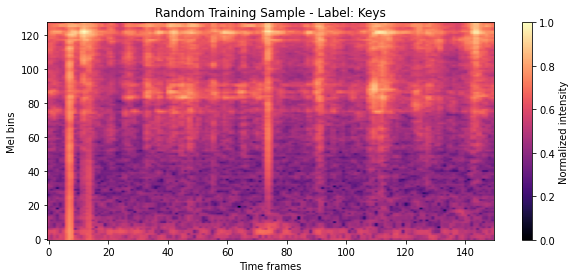

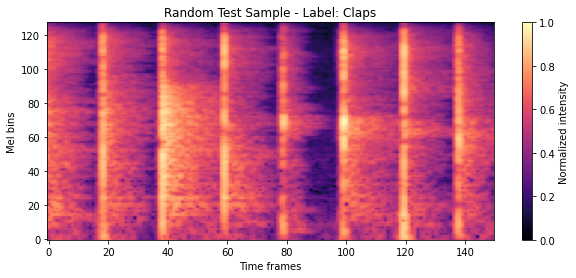

In [9]:
import random

def display_random_entry():
    # Random training example
    train_idx = random.randint(0, len(dataset)-1)
    mel_train, label_train = dataset[train_idx]

    plt.figure(figsize=(10, 4))
    plt.imshow(mel_train[:, :, 0], origin='lower', aspect='auto', cmap='magma')
    plt.colorbar(label='Normalized intensity')
    plt.title(f"Random Training Sample - Label: {CATEGORIES[label_train]}")
    plt.xlabel("Time frames")
    plt.ylabel("Mel bins")
    plt.show()

    # Random test example
    test_idx = random.randint(0, len(test_dataset)-1)
    mel_test, label_test = test_dataset[test_idx]

    plt.figure(figsize=(10, 4))
    plt.imshow(mel_test[:, :, 0], origin='lower', aspect='auto', cmap='magma')
    plt.colorbar(label='Normalized intensity')
    plt.title(f"Random Test Sample - Label: {CATEGORIES[label_test]}")
    plt.xlabel("Time frames")
    plt.ylabel("Mel bins")
    plt.show()

# Call the function
display_random_entry()

Shuffle the dataset and make sure by looking at the labels.

In [13]:
import random

random.shuffle(dataset)

# choose an arbitrary size and truncate
MAX_SAMPLES = 9000
dataset = dataset[:MAX_SAMPLES]
print(f"Shuffled and truncated dataset to {len(dataset)} samples.")

for sample in dataset[:30]:
    print(sample[1])

Shuffled and truncated dataset to 765 samples.
1
0
0
1
0
2
2
0
1
1
1
2
2
0
1
2
1
2
2
2
2
0
2
1
1
2
0
2
1
1


Create your train and test split.

In [14]:
# Train set
x_train, y_train = [], []

for spectrogram, label in dataset:   # <-- only 2 values
    x_train.append(spectrogram)
    y_train.append(label)

# LOSO test set
x_test, y_test = [], []

for spectrogram, label in test_dataset:  # <-- only 2 values
    x_test.append(spectrogram)
    y_test.append(label)

x_train = np.array(x_train)
y_train = np.array(y_train)

x_test  = np.array(x_test)
y_test  = np.array(y_test)

print("x_train shape:", x_train.shape)
print("x_test shape :", x_test.shape)
print("Train labels:", Counter(y_train))
print("Test labels :", Counter(y_test))


x_train shape: (765, 128, 150, 1)
x_test shape : (255, 128, 150, 1)
Train labels: Counter({1: 255, 0: 255, 2: 255})
Test labels : Counter({0: 85, 1: 85, 2: 85})


In [15]:
# Initialize feature and label lists
x_train, y_train = [], []
x_test, y_test   = [], []

# --- Train set ---
for mel_spec, label in dataset:
    x_train.append(mel_spec)
    y_train.append(label)

# --- LOSO test set ---
for mel_spec, label in test_dataset:
    x_test.append(mel_spec)
    y_test.append(label)

# Convert lists to NumPy arrays
x_train = np.array(x_train)
y_train = np.array(y_train)

x_test  = np.array(x_test)
y_test  = np.array(y_test)

# --- Print shapes and label distribution ---
print("x_train shape:", x_train.shape)  # (num_train_samples, n_mels, T_SAMP, 1)
print("x_test  shape:", x_test.shape)   # (num_test_samples, n_mels, T_SAMP, 1)
print("Train labels:", Counter(y_train))
print("Test labels :", Counter(y_test))

x_train shape: (765, 128, 150, 1)
x_test  shape: (255, 128, 150, 1)
Train labels: Counter({1: 255, 0: 255, 2: 255})
Test labels : Counter({0: 85, 1: 85, 2: 85})


## Network architecture

In [16]:
import keras
import tensorflow as tf

print("keras:", keras.__version__)
print("tf:", tf.__version__)


keras: 2.6.0
tf: 2.6.2


## Model training

In [17]:
# Model definition (simplified & regularized)
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout, BatchNormalization, GlobalAveragePooling2D
from tensorflow.keras.regularizers import l2
from tensorflow.keras.optimizers import Adam

input_shape = x_train.shape[1:]  # (n_mels, time_steps, 1)

model = Sequential([
    # Conv Block 1
    Conv2D(
        filters=16,            # number of output channels
        kernel_size=(3,7),     # convolution window
        strides=(1,2),         # move steps in height and width
        activation='relu',
        padding='same',
        input_shape=input_shape
    ),
    BatchNormalization(),
    MaxPooling2D((2,2)),
    Dropout(0.3),
    
    # Conv Block 3
    Conv2D(16, (3,3), activation='relu', padding='same'),
    BatchNormalization(),
    GlobalAveragePooling2D(),  # reduces parameters and prevents overfitting
    
    # Dense + Output
    Dense(8, activation='relu'),
    BatchNormalization(),
    Dropout(0.4),
    
    Dense(len(CATEGORIES), activation='softmax')
])

# Use a smaller learning rate to stabilise training
model.compile(
    optimizer=Adam(learning_rate=1e-5),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

Model: "sequential"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
conv2d (Conv2D)              (None, 128, 75, 16)       352       
_________________________________________________________________
batch_normalization (BatchNo (None, 128, 75, 16)       64        
_________________________________________________________________
max_pooling2d (MaxPooling2D) (None, 64, 37, 16)        0         
_________________________________________________________________
dropout (Dropout)            (None, 64, 37, 16)        0         
_________________________________________________________________
conv2d_1 (Conv2D)            (None, 64, 37, 16)        2320      
_________________________________________________________________
batch_normalization_1 (Batch (None, 64, 37, 16)        64        
_________________________________________________________________
global_average_pooling2d (Gl (None, 16)                0

Epoch 1/40
24/24 - 3s - loss: 0.5349 - accuracy: 0.7961 - val_loss: 0.9669 - val_accuracy: 0.4392
Epoch 2/40
24/24 - 3s - loss: 0.5149 - accuracy: 0.8235 - val_loss: 0.9846 - val_accuracy: 0.4314
Epoch 3/40
24/24 - 4s - loss: 0.5264 - accuracy: 0.8170 - val_loss: 0.9795 - val_accuracy: 0.4314
Epoch 4/40
24/24 - 4s - loss: 0.5405 - accuracy: 0.8196 - val_loss: 0.9823 - val_accuracy: 0.4314
Epoch 5/40
24/24 - 4s - loss: 0.5419 - accuracy: 0.8183 - val_loss: 0.9919 - val_accuracy: 0.4314
Epoch 6/40
24/24 - 4s - loss: 0.5449 - accuracy: 0.8013 - val_loss: 0.9758 - val_accuracy: 0.4392
Epoch 7/40
24/24 - 3s - loss: 0.5111 - accuracy: 0.8235 - val_loss: 0.9808 - val_accuracy: 0.4353
Epoch 8/40
24/24 - 4s - loss: 0.5307 - accuracy: 0.8157 - val_loss: 0.9741 - val_accuracy: 0.4353
Epoch 9/40
24/24 - 4s - loss: 0.5245 - accuracy: 0.8105 - val_loss: 0.9801 - val_accuracy: 0.4196
Epoch 10/40
24/24 - 3s - loss: 0.5352 - accuracy: 0.8052 - val_loss: 0.9827 - val_accuracy: 0.4196
Epoch 11/40
24/24 -

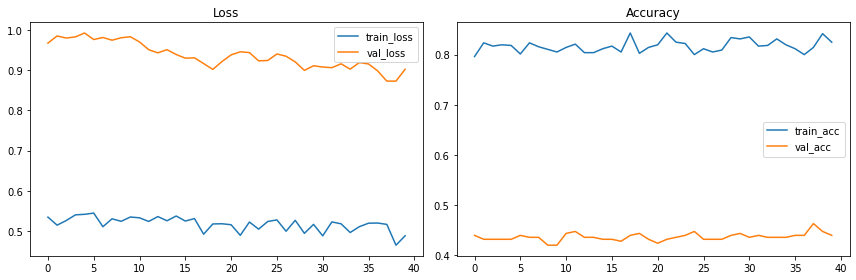

In [20]:
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping, ReduceLROnPlateau

# Training config
EPOCHS = 40
checkpoint_cb = ModelCheckpoint('best_model.keras', save_best_only=True, monitor='val_loss', mode='min')
earlystop_cb = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)
reduce_lr_cb = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=10, min_lr=1e-6)

history = model.fit(
    x_train, y_train,
    epochs=EPOCHS,
    #batch_size=batch,
    validation_data=(x_test, y_test),
    #callbacks=[checkpoint_cb, earlystop_cb, reduce_lr_cb],
    verbose=2
)

# Evaluate and save final model
test_loss, test_acc = model.evaluate(x_test, y_test, verbose=2)
print(f"Test loss: {test_loss:.4f}, Test accuracy: {test_acc:.4f}")
#model.save("final_model.h5")

# Plot training history
plt.figure(figsize=(12,4))
plt.subplot(1,2,1)
plt.plot(history.history['loss'], label='train_loss')
plt.plot(history.history['val_loss'], label='val_loss')
plt.legend(); plt.title('Loss')

plt.subplot(1,2,2)
plt.plot(history.history['accuracy'], label='train_acc')
plt.plot(history.history['val_accuracy'], label='val_acc')
plt.legend(); plt.title('Accuracy')

plt.tight_layout()
plt.show()

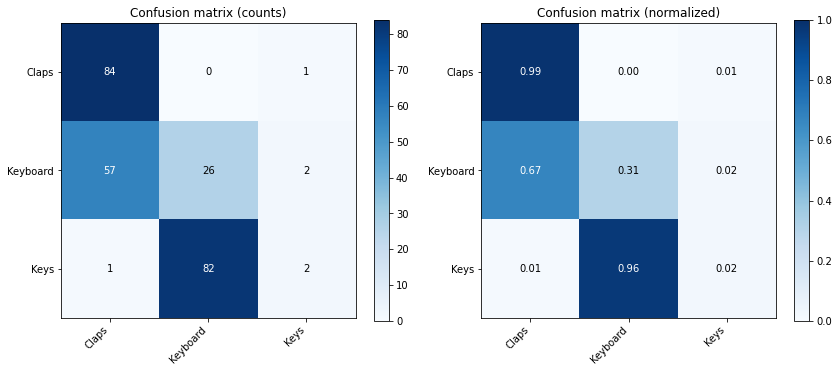

Classification report:
Using in-memory model instance


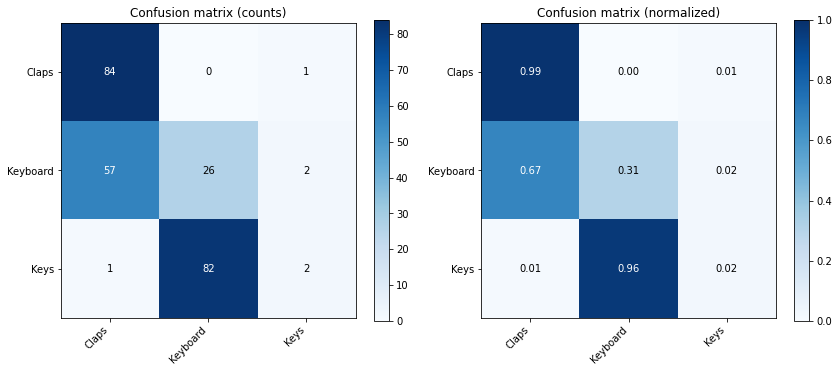

Classification report:
              precision    recall  f1-score   support

       Claps       0.59      0.99      0.74        85
    Keyboard       0.24      0.31      0.27        85
        Keys       0.40      0.02      0.04        85

    accuracy                           0.44       255
   macro avg       0.41      0.44      0.35       255
weighted avg       0.41      0.44      0.35       255



In [21]:
from sklearn.metrics import confusion_matrix, classification_report
from tensorflow.keras.models import load_model
import os
import numpy as np

# Confusion matrix and classification report for the trained model

import matplotlib.pyplot as plt

# Predict labels for the test set
y_prob = model.predict(x_test, verbose=0)
y_pred = np.argmax(y_prob, axis=1)

# Compute confusion matrix (counts) and normalized version
cm = confusion_matrix(y_test, y_pred)
cm_norm = cm.astype('float') / (cm.sum(axis=1)[:, np.newaxis] + 1e-12)  # avoid div by zero

# Plot both count and normalized confusion matrices side-by-side
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Counts
im0 = axes[0].imshow(cm, interpolation='nearest', cmap=plt.cm.Blues)
axes[0].set_title("Confusion matrix (counts)")
plt.colorbar(im0, ax=axes[0])
ticks = np.arange(len(CATEGORIES))
axes[0].set_xticks(ticks); axes[0].set_yticks(ticks)
axes[0].set_xticklabels(CATEGORIES, rotation=45, ha='right')
axes[0].set_yticklabels(CATEGORIES)
thresh = cm.max() / 2.
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        axes[0].text(j, i, f"{cm[i, j]:d}",
                     ha='center', va='center',
                     color='white' if cm[i, j] > thresh else 'black')

# Normalized
im1 = axes[1].imshow(cm_norm, interpolation='nearest', cmap=plt.cm.Blues, vmin=0, vmax=1)
axes[1].set_title("Confusion matrix (normalized)")
plt.colorbar(im1, ax=axes[1])
axes[1].set_xticks(ticks); axes[1].set_yticks(ticks)
axes[1].set_xticklabels(CATEGORIES, rotation=45, ha='right')
axes[1].set_yticklabels(CATEGORIES)
for i in range(cm_norm.shape[0]):
    for j in range(cm_norm.shape[1]):
        axes[1].text(j, i, f"{cm_norm[i, j]:.2f}",
                     ha='center', va='center',
                     color='white' if cm_norm[i, j] > 0.5 else 'black')

plt.tight_layout()
plt.show()

# Print classification report
print("Classification report:")
import matplotlib.pyplot as plt

# Use in-memory model instance
if 'model' not in globals():
    raise RuntimeError("No model instance found in memory. Train or load a model before running this cell.")
else:
    print("Using in-memory model instance")

# Predict labels for the test set
y_prob = model.predict(x_test, verbose=0)
y_pred = np.argmax(y_prob, axis=1)

# Compute confusion matrix (counts) and normalized version
cm = confusion_matrix(y_test, y_pred)
cm_norm = cm.astype('float') / (cm.sum(axis=1)[:, np.newaxis] + 1e-12)  # avoid div by zero

# Plot both count and normalized confusion matrices side-by-side
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Counts
im0 = axes[0].imshow(cm, interpolation='nearest', cmap=plt.cm.Blues)
axes[0].set_title("Confusion matrix (counts)")
plt.colorbar(im0, ax=axes[0])
ticks = np.arange(len(CATEGORIES))
axes[0].set_xticks(ticks); axes[0].set_yticks(ticks)
axes[0].set_xticklabels(CATEGORIES, rotation=45, ha='right')
axes[0].set_yticklabels(CATEGORIES)
thresh = cm.max() / 2.
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        axes[0].text(j, i, f"{cm[i, j]:d}",
                     ha='center', va='center',
                     color='white' if cm[i, j] > thresh else 'black')

# Normalized
im1 = axes[1].imshow(cm_norm, interpolation='nearest', cmap=plt.cm.Blues, vmin=0, vmax=1)
axes[1].set_title("Confusion matrix (normalized)")
plt.colorbar(im1, ax=axes[1])
axes[1].set_xticks(ticks); axes[1].set_yticks(ticks)
axes[1].set_xticklabels(CATEGORIES, rotation=45, ha='right')
axes[1].set_yticklabels(CATEGORIES)
for i in range(cm_norm.shape[0]):
    for j in range(cm_norm.shape[1]):
        axes[1].text(j, i, f"{cm_norm[i, j]:.2f}",
                     ha='center', va='center',
                     color='white' if cm_norm[i, j] > 0.5 else 'black')

plt.tight_layout()
plt.show()

# Print classification report
print("Classification report:")
print(classification_report(y_test, y_pred, target_names=CATEGORIES))

Save your model to old tf2.7.0-compatible version

In [22]:
from datetime import datetime

timestamp = datetime.now().strftime("%Y-%m-%d_%H-%M-%S")
filename = f"model_tf27_{timestamp}.h5"

# SAVE IN TF 2.7–COMPATIBLE FORMAT
model.save(
    filename,
    include_optimizer=False
)

print("")
print("model saved as: " + filename)
print("")


model saved as: model_tf27_2026-01-18_19-17-04.h5



In [23]:
print("Test label counts:", Counter(y_test))

Test label counts: Counter({0: 85, 1: 85, 2: 85})
